In [1]:
import numpy as np # Для численных операций
import pandas as pd # Для работы с табличными данными
import matplotlib.pyplot as plt # Для построения графиков
import seaborn as sns # Для улучшенной визуализации
from scipy import stats # Для статистических функций, например, нормального распределения
import random # Для случайных операций, в частности для тасования
from tqdm import tqdm # Для визуализации процесса циклов
from matplotlib.ticker import FuncFormatter # для форматирования графиков


pd.set_option('display.max_rows', 1000)
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 1000)

sns.set_theme(style="whitegrid", font_scale=1.1)
palette = sns.color_palette('viridis')
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

In [2]:
result = pd.read_parquet('result.parquet')

In [3]:
gom = pd.read_parquet('homogenuity.parquet')

In [4]:
mde = pd.read_parquet('mde.parquet')

# EDA

In [6]:
mde = pd.read_parquet('mde.parquet')
homogenuity = pd.read_parquet('homogenuity.parquet')
result = pd.read_parquet('result.parquet')
print('MDE:', ' ', mde.shape)
display(mde.head(3))
print('')
print('homogenuity:', ' ', homogenuity.shape)
display(homogenuity.head(3))
print('')
print('result:', ' ', result.shape)
display(result.head(3))

MDE:   (1030254, 8)


,grp,user_id,bu,parent_name,subject_name,orders_sum,gmv_sum,pre_week
0,3prc_decrease,3AA5131827F681CA1569B2C7BD9546FA,Fashion,Одежда,Джинсы,840.00,840.00,5
1,5prc_increase,8269A64F5696B36F1634A90BD4419377,Fashion,Одежда,Джинсы,1783.75,1783.75,7
2,control,921E6DE789878E1BC52FF621B1B86839,Fashion,Одежда,Джинсы,1497.50,0.00,4



homogenuity:   (571116, 23)


,user_id,grp,bu,parent_name,subject_name,created_orders_cnt,created_items_cnt,created_items_rub,bought_items_cnt,bought_items_rub,spp_rub,spp_pct,order_days_cnt,aiv,aov,upt,age,gender,profit,purchase_percent,purchase_sum,locale,region
0,A2CA63EB39325D4FC044FBFD2CC2FF33,control,Fashion,Одежда,Джинсы,10,10,22950.00,6,10833.75,4312.5,0.158184,2,2295.000,2295.000,1.0,<NA>,<NA>,51835198,42,170956900,ru-msk,<NA>
1,8045B13C76AEFFDA8BEBBB6127B06678,control,Fashion,Одежда,Джинсы,4,4,3640.00,2,1820.00,2107.5,0.405288,1,910.000,910.000,1.0,<NA>,<NA>,8426101,77,27377000,ru-sfo,<NA>
2,5D2F49AE4BB877B2F852D5C9E17F2E07,1prc_increase,Fashion,Одежда,Джинсы,2,2,2093.75,0,0.00,705.0,0.255782,1,1046.875,1046.875,1.0,<NA>,<NA>,5172215,34,24521400,ru-pfo,<NA>



result:   (1328879, 11)


,grp,user_id,bu,parent_name,subject_name,created_items_cnt,spp_pct,spp_rub,orders_rub,sales_rub,supplier_price
0,5prc_decrease,2958380FD4A91A445780DE061A44E090,Fashion,Одежда,Джинсы,3,0.301519,2259.375,5643.75,0.000,7653.125
1,5prc_decrease,233982E5C3D7464C299B00605B460E9A,Fashion,Одежда,Джинсы,4,0.357019,5888.750,10742.50,2090.000,16631.250
2,1prc_decrease,EB001560B92FD8EA77C77AAA2F2A12EA,Fashion,Одежда,Джинсы,5,0.322821,1967.500,4281.25,803.125,6085.625


In [7]:
def descriptive_statistics(df):
    display(df.shape)
    display(df.info())
    display(df.describe())
    print('ДУБЛИКАТЫ:','\n')
    print(df[df.duplicated()])
    print('\n')
    print('NaNs, доля:', '\n')
    print(df.isna().sum()/df.shape[0])

In [8]:
descriptive_statistics(mde)

(1030254, 8)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030254 entries, 0 to 1030253
Data columns (total 8 columns):
 #   Column        Non-Null Count    Dtype  
---  ------        --------------    -----  
 0   grp           1030254 non-null  string 
 1   user_id       1030254 non-null  string 
 2   bu            1030254 non-null  string 
 3   parent_name   1030254 non-null  string 
 4   subject_name  1030254 non-null  string 
 5   orders_sum    1030254 non-null  float64
 6   gmv_sum       1030254 non-null  float64
 7   pre_week      1030254 non-null  int64  
dtypes: float64(2), int64(1), string(5)
memory usage: 62.9 MB


None

,orders_sum,gmv_sum,pre_week
count,1.030254e+06,1.030254e+06,1.030254e+06
mean,6.230323e+03,1.791011e+03,3.932261e+00
std,6.046083e+03,2.125972e+03,2.186614e+00
min,3.750000e+01,0.000000e+00,1.000000e+00
25%,2.632500e+03,0.000000e+00,2.000000e+00
50%,4.223750e+03,1.383750e+03,4.000000e+00
75%,7.716250e+03,3.189062e+03,6.000000e+00
max,4.167888e+05,7.251125e+04,8.000000e+00


ДУБЛИКАТЫ: 

Empty DataFrame
Columns: [grp, user_id, bu, parent_name, subject_name, orders_sum, gmv_sum, pre_week]
Index: []


NaNs, доля: 

grp             0.0
user_id         0.0
bu              0.0
parent_name     0.0
subject_name    0.0
orders_sum      0.0
gmv_sum         0.0
pre_week        0.0
dtype: float64


In [9]:
descriptive_statistics(homogenuity)

(571116, 23)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 571116 entries, 0 to 571115
Data columns (total 23 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   user_id             571116 non-null  string 
 1   grp                 571116 non-null  string 
 2   bu                  571116 non-null  string 
 3   parent_name         571116 non-null  string 
 4   subject_name        571116 non-null  string 
 5   created_orders_cnt  571116 non-null  uint64 
 6   created_items_cnt   571116 non-null  uint64 
 7   created_items_rub   571116 non-null  float64
 8   bought_items_cnt    571116 non-null  uint64 
 9   bought_items_rub    571116 non-null  float64
 10  spp_rub             571116 non-null  float64
 11  spp_pct             571116 non-null  float64
 12  order_days_cnt      571116 non-null  uint64 
 13  aiv                 571116 non-null  float64
 14  aov                 571116 non-null  float64
 15  upt                 571116 non-nul

None

,created_orders_cnt,created_items_cnt,created_items_rub,bought_items_cnt,bought_items_rub,spp_rub,spp_pct,order_days_cnt,aiv,aov,upt,age,profit,purchase_percent,purchase_sum
count,571116.000000,571116.000000,571116.000000,571116.000000,571116.000000,571116.000000,571116.000000,571116.000000,571116.000000,571116.000000,571116.0,0.0,5.711160e+05,571116.000000,5.711160e+05
mean,5.240967,5.240967,8190.966289,1.540678,2302.426999,2715.225002,0.254448,1.457716,1525.688159,1525.688159,1.0,<NA>,8.817409e+06,58.990853,3.155942e+07
std,4.665409,4.665409,8678.474036,1.480741,2505.255431,2931.158100,0.073445,0.891690,642.999228,642.999228,0.0,<NA>,1.158610e+07,19.120218,4.241856e+07
min,2.000000,2.000000,52.500000,0.000000,0.000000,-2175.275574,-0.962614,1.000000,26.250000,26.250000,1.0,<NA>,-1.387263e+07,0.000000,0.000000e+00
25%,2.000000,2.000000,3093.750000,0.000000,0.000000,970.000000,0.198728,1.000000,1079.791667,1079.791667,1.0,<NA>,3.137135e+06,45.000000,1.176390e+07
50%,4.000000,4.000000,5411.250000,2.000000,2126.250000,1770.000000,0.258621,1.000000,1501.562500,1501.562500,1.0,<NA>,6.420997e+06,57.000000,2.304640e+07
75%,6.000000,6.000000,10130.000000,2.000000,3616.250000,3396.250000,0.306057,2.000000,1884.375000,1884.375000,1.0,<NA>,1.151480e+07,73.000000,4.065402e+07
max,138.000000,138.000000,306358.750000,78.000000,146961.250000,124077.500000,0.640724,22.000000,19023.750000,19023.750000,1.0,<NA>,1.931399e+09,100.000000,5.772721e+09


ДУБЛИКАТЫ: 

Empty DataFrame
Columns: [user_id, grp, bu, parent_name, subject_name, created_orders_cnt, created_items_cnt, created_items_rub, bought_items_cnt, bought_items_rub, spp_rub, spp_pct, order_days_cnt, aiv, aov, upt, age, gender, profit, purchase_percent, purchase_sum, locale, region]
Index: []


NaNs, доля: 

user_id               0.0
grp                   0.0
bu                    0.0
parent_name           0.0
subject_name          0.0
created_orders_cnt    0.0
created_items_cnt     0.0
created_items_rub     0.0
bought_items_cnt      0.0
bought_items_rub      0.0
spp_rub               0.0
spp_pct               0.0
order_days_cnt        0.0
aiv                   0.0
aov                   0.0
upt                   0.0
age                   1.0
gender                1.0
profit                0.0
purchase_percent      0.0
purchase_sum          0.0
locale                0.0
region                1.0
dtype: float64


In [10]:
descriptive_statistics(result)

(1328879, 11)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1328879 entries, 0 to 1328878
Data columns (total 11 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   grp                1328879 non-null  string 
 1   user_id            1328879 non-null  string 
 2   bu                 1328879 non-null  string 
 3   parent_name        1328879 non-null  string 
 4   subject_name       1328879 non-null  string 
 5   created_items_cnt  1328879 non-null  uint64 
 6   spp_pct            1328879 non-null  float64
 7   spp_rub            1328879 non-null  float64
 8   orders_rub         1328879 non-null  float64
 9   sales_rub          1328879 non-null  float64
 10  supplier_price     1328879 non-null  float64
dtypes: float64(5), string(5), uint64(1)
memory usage: 111.5 MB


None

,created_items_cnt,spp_pct,spp_rub,orders_rub,sales_rub,supplier_price
count,1.328879e+06,1.328879e+06,1.328879e+06,1.328879e+06,1.328879e+06,1.328879e+06
mean,3.437157e+00,2.821944e-01,2.102741e+03,5.419516e+03,1.391236e+03,7.310977e+03
std,3.512797e+00,7.640090e-02,2.569292e+03,6.351575e+03,1.558786e+03,8.526231e+03
min,1.000000e+00,-2.598214e-01,-5.303544e+03,4.000000e+01,0.000000e+00,6.250000e+01
25%,1.000000e+00,2.351830e-01,6.487500e+02,1.778125e+03,0.000000e+00,2.406250e+03
50%,2.000000e+00,2.868951e-01,1.288125e+03,3.452500e+03,1.255000e+03,4.678125e+03
75%,4.000000e+00,3.344392e-01,2.588750e+03,6.656875e+03,1.969906e+03,8.996250e+03
max,2.680000e+02,5.554441e-01,1.561269e+05,5.484475e+05,1.668344e+05,6.643119e+05


ДУБЛИКАТЫ: 

Empty DataFrame
Columns: [grp, user_id, bu, parent_name, subject_name, created_items_cnt, spp_pct, spp_rub, orders_rub, sales_rub, supplier_price]
Index: []


NaNs, доля: 

grp                  0.0
user_id              0.0
bu                   0.0
parent_name          0.0
subject_name         0.0
created_items_cnt    0.0
spp_pct              0.0
spp_rub              0.0
orders_rub           0.0
sales_rub            0.0
supplier_price       0.0
dtype: float64


In [11]:
def plot_group_sizes(df, user_col='user_id', title='Размер групп'):
    stat = (
        df.groupby('grp')[user_col]
          .nunique()
          .sort_values(ascending=False)
          .reset_index(name='users')
    )
    stat['share'] = stat['users'] / stat['users'].sum()

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    sns.barplot(data=stat, x='grp', y='users', ax=axes[0])
    axes[0].set_title(title)
    axes[0].tick_params(axis='x', rotation=30)

    sns.barplot(data=stat, x='grp', y='share', ax=axes[1])
    axes[1].set_title('Доля пользователей по группам')
    axes[1].tick_params(axis='x', rotation=30)

    plt.tight_layout()
    display(stat)

,grp,users,share
0,5prc_decrease,201669,0.151759
1,3prc_decrease,196417,0.147807
2,1prc_decrease,191954,0.144448
3,control,189717,0.142765
4,1prc_increase,187106,0.140800
5,3prc_increase,183368,0.137987
6,5prc_increase,178648,0.134435


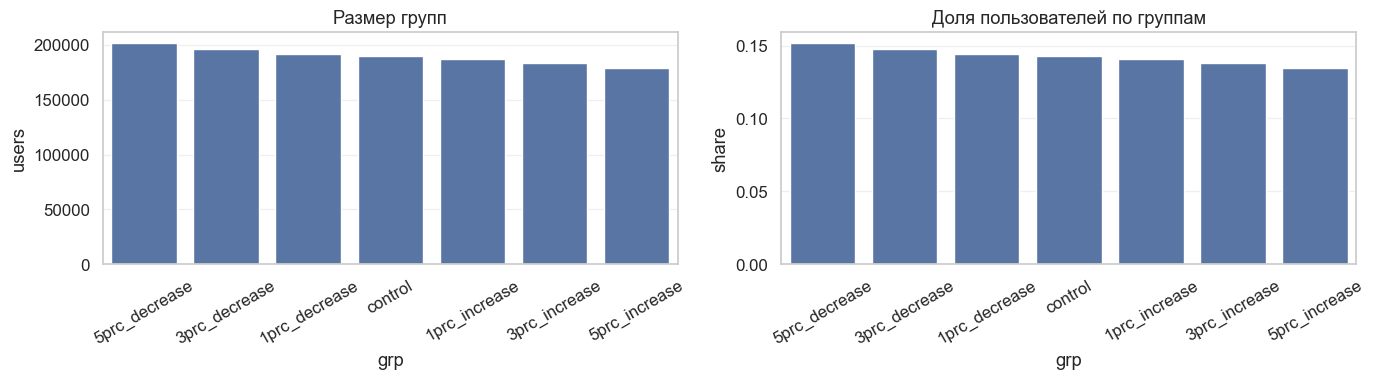

In [12]:
plot_group_sizes(result)

Вывод:

Группы немного различаются по размеру, но дисбаланс умеренный и не выглядит критичным. Сравнение групп корректнее проводить в метриках на пользователя, а не по абсолютным суммам.

In [14]:
def plot_preperiod_boxplots(df, metrics, cols=3):
    rows = int(np.ceil(len(metrics) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(5*cols, 4*rows))
    axes = np.array(axes).reshape(-1)

    for ax, metric in zip(axes, metrics):
        sns.boxplot(data=df, x='grp', y=metric, showfliers=False, ax=ax)
        ax.set_title(metric)
        ax.tick_params(axis='x', rotation=30)

    for ax in axes[len(metrics):]:
        ax.axis('off')

    plt.tight_layout()

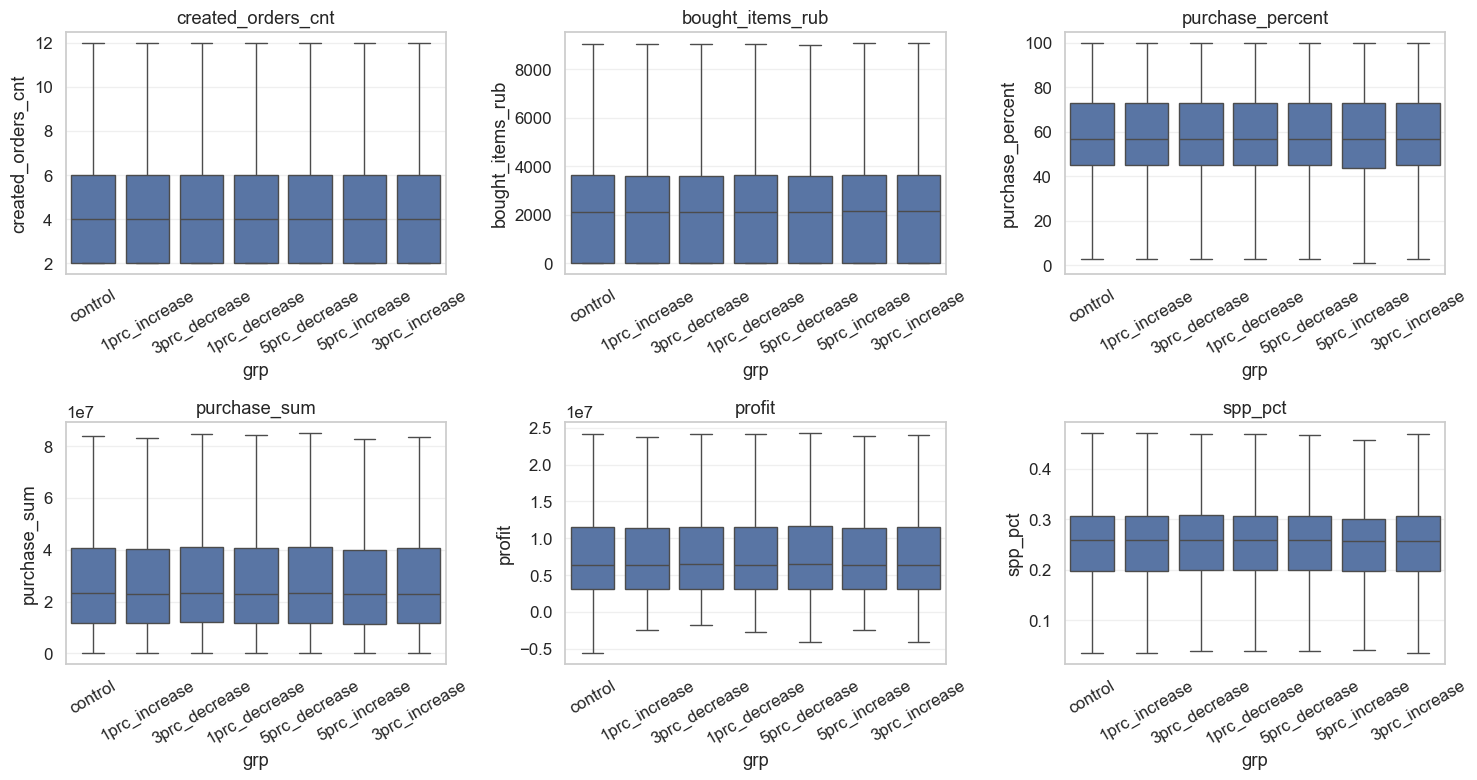

In [15]:
plot_preperiod_boxplots(
    homogenuity,
    ['created_orders_cnt', 'bought_items_rub', 'purchase_percent', 'purchase_sum', 'profit', 'spp_pct'],
    cols=3
)

Вывод:

По основным предпериодным метрикам группы выглядят очень близкими: средние и медианы почти совпадают, систематического смещения не видно. Это сильный аргумент в пользу того, что экспериментальные различия дальше можно связывать именно с изменением СПП.

In [17]:
def treatment_summary(df):
    stat = (
        df.groupby('grp')[['spp_pct', 'spp_rub']]
          .agg(['mean', 'median', 'std'])
          .round(4)
    )
    return stat

In [18]:
treatment_summary(result)

spp_pct                    spp_rub                    
                 mean  median     std       mean   median        std
grp                                                                 
1prc_decrease  0.2883  0.2929  0.0726  2149.4104  1327.50  2588.8903
1prc_increase  0.2740  0.2787  0.0738  2025.1956  1240.00  2473.1046
3prc_decrease  0.3021  0.3071  0.0720  2280.0974  1408.75  2761.2671
3prc_increase  0.2607  0.2653  0.0743  1920.4199  1176.25  2357.7747
5prc_decrease  0.3163  0.3213  0.0713  2377.0598  1477.50  2847.4575
5prc_increase  0.2467  0.2510  0.0751  1815.3145  1100.00  2222.5099
control        0.2814  0.2861  0.0733  2103.6587  1293.75  2580.2719

In [19]:
def plot_treatment_shift(df):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    sns.boxplot(data=df, x='grp', y='spp_pct', showfliers=False, ax=axes[0])
    axes[0].set_title('Распределение spp_pct по группам')
    axes[0].tick_params(axis='x', rotation=30)

    sns.boxplot(data=df, x='grp', y='spp_rub', showfliers=False, ax=axes[1])
    axes[1].set_title('Распределение spp_rub по группам')
    axes[1].tick_params(axis='x', rotation=30)

    plt.tight_layout()

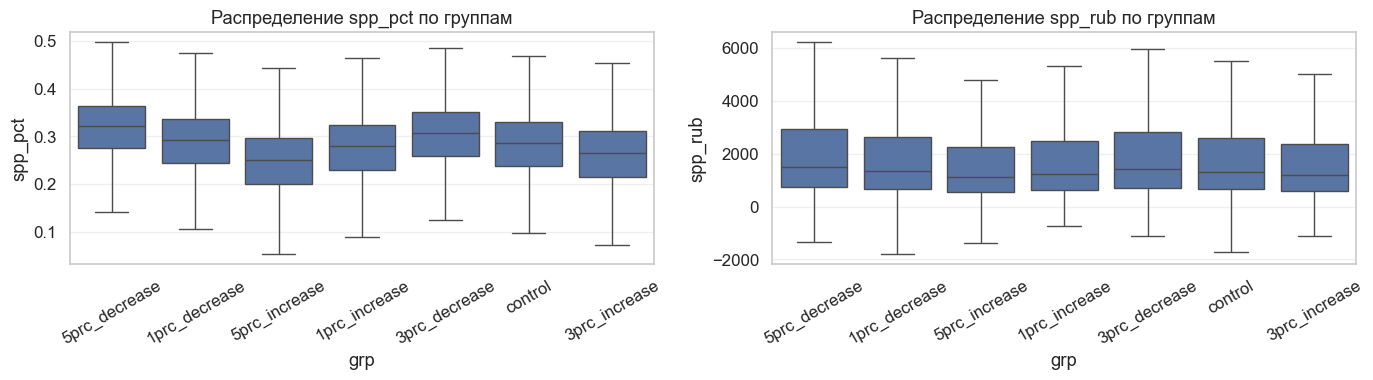

In [20]:
plot_treatment_shift(result)

Вывод:

Фактическое treatment-воздействие есть: группы упорядочены монотонно, а контроль находится между increase- и decrease-ветками. Это значит, что эксперимент не “размылся”, и изменение СПП действительно дошло до пользователей.



In [22]:
def plot_post_boxplots(df, metrics, cols=3):
    rows = int(np.ceil(len(metrics) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(5*cols, 4*rows))
    axes = np.array(axes).reshape(-1)

    for ax, metric in zip(axes, metrics):
        sns.boxplot(data=df, x='grp', y=metric, showfliers=False, ax=ax)
        ax.set_title(metric)
        ax.tick_params(axis='x', rotation=30)

    for ax in axes[len(metrics):]:
        ax.axis('off')

    plt.tight_layout()

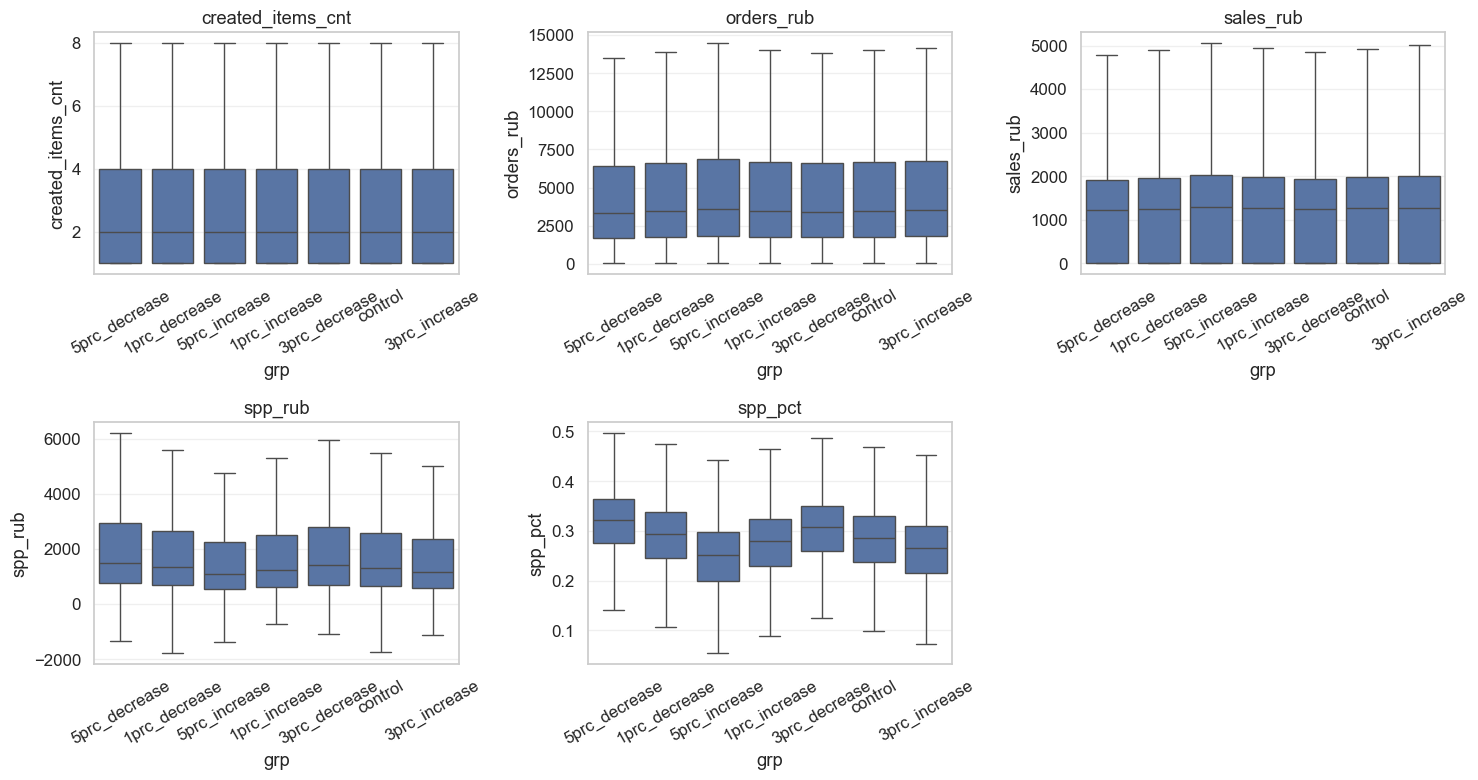

In [23]:
post_metrics = ['created_items_cnt', 'orders_rub', 'sales_rub', 'spp_rub', 'spp_pct']
plot_post_boxplots(result, post_metrics, cols=3)

Вывод:

По post-period метрикам различия между группами уже заметнее, чем в предпериоде, особенно по spp_pct и spp_rub. Для денежных метрик визуально сохраняется сильная вариативность, поэтому дальше желательно опираться не только на средние, но и на медианы и user-level агрегацию.

In [25]:
def quantile_report(df, cols, qs=(0.5, 0.9, 0.95, 0.99, 0.999)):
    stat = df[cols].quantile(qs).T.round(3)
    return stat

In [26]:
quantile_report(result, ['orders_rub', 'sales_rub', 'spp_rub'])

,0.500,0.900,0.950,0.990,0.999
orders_rub,3452.500,11809.375,16443.125,30180.000,59976.860
sales_rub,1255.000,3137.500,4066.875,6685.762,12317.180
spp_rub,1288.125,4700.000,6610.000,12234.512,24296.403


In [27]:
def plot_log_distributions(df, metrics, cols=2):
    rows = int(np.ceil(len(metrics) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(6*cols, 4*rows))
    axes = np.array(axes).reshape(-1)

    for ax, metric in zip(axes, metrics):
        sns.histplot(np.log1p(df[metric]), bins=60, ax=ax)
        ax.set_title(f'log1p({metric})')

    for ax in axes[len(metrics):]:
        ax.axis('off')

    plt.tight_layout()

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/arraylike.py:396: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


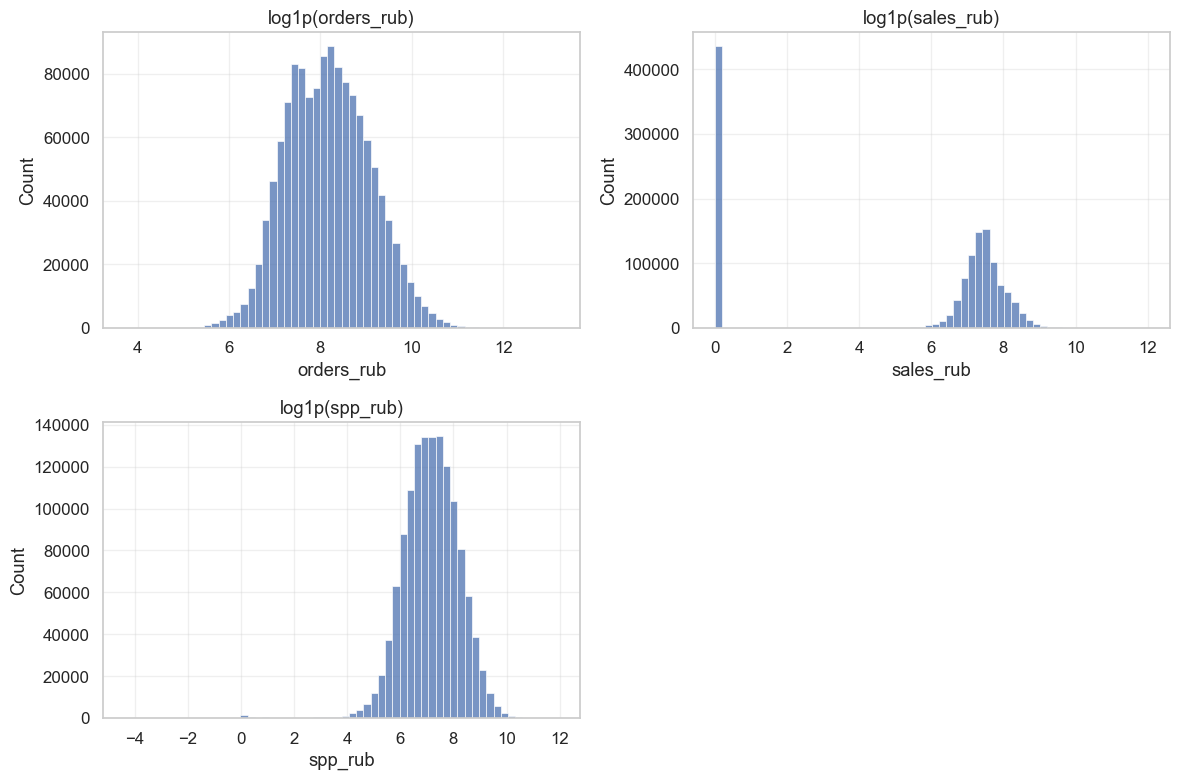

In [28]:

plot_log_distributions(result, ['orders_rub', 'sales_rub', 'spp_rub'], cols=2)

Вывод:

У денежных метрик выраженный heavy tail: верхние квантили сильно удалены от медианы. Это нормальная ситуация для e-commerce, но она означает, что при дальнейшей оценке эффекта нужно проверять устойчивость результатов к выбросам.

In [30]:
def zero_share(df, metrics):
    stat = (
        df.groupby('grp')[metrics]
          .apply(lambda x: (x == 0).mean())
          .T
          .round(4)
    )
    return stat

In [31]:
zero_share(result, ['orders_rub', 'sales_rub', 'spp_rub'])

grp,1prc_decrease,1prc_increase,3prc_decrease,3prc_increase,5prc_decrease,5prc_increase,control
orders_rub,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
sales_rub,0.3254,0.3310,0.3229,0.3344,0.3195,0.3373,0.3289
spp_rub,0.0011,0.0013,0.0010,0.0012,0.0009,0.0012,0.0011


In [32]:
def plot_zero_share(df, metric='sales_rub'):
    stat = (
        df.groupby('grp')[metric]
          .apply(lambda x: (x == 0).mean())
          .reset_index(name='zero_share')
          .sort_values('zero_share')
    )

    plt.figure(figsize=(8, 4))
    sns.barplot(data=stat, x='grp', y='zero_share')
    plt.title(f'Доля нулевых значений: {metric}')
    plt.xticks(rotation=30)
    plt.show()

    display(stat)

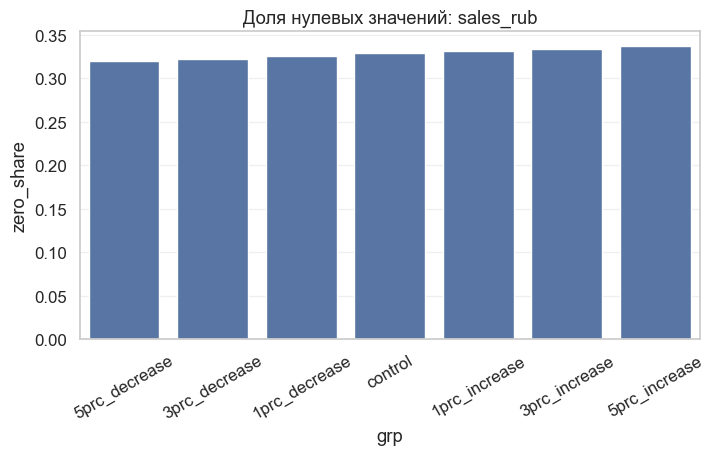

,grp,zero_share
4,5prc_decrease,0.319474
2,3prc_decrease,0.322890
0,1prc_decrease,0.325370
6,control,0.328943
1,1prc_increase,0.331037
3,3prc_increase,0.334404
5,5prc_increase,0.337289


In [33]:
plot_zero_share(result, 'sales_rub')

Вывод:

По sales_rub доля нулей заметно варьируется между группами, и это уже похоже на различие в конверсии в выкуп. Этот сигнал особенно важен, потому что именно фактический выкуп, а не создание заказа, формирует реальный бизнес-эффект.

In [35]:
def build_user_level(result):
    user_df = (
        result.groupby(['grp', 'user_id'], as_index=False)
              .agg(
                  created_items_cnt=('created_items_cnt', 'sum'),
                  orders_rub=('orders_rub', 'sum'),
                  sales_rub=('sales_rub', 'sum'),
                  spp_rub=('spp_rub', 'sum'),
                  avg_spp_pct=('spp_pct', 'mean')
              )
    )
    return user_df

In [36]:
user_result = build_user_level(result)
user_result.head()

,grp,user_id,created_items_cnt,orders_rub,sales_rub,spp_rub,avg_spp_pct
0,1prc_decrease,00001D81B912895FBADF4A7B8B0663A1,2,1666.250,0.00,210.000,0.116310
1,1prc_decrease,00003687F40AB9B083E16D4417A0EC1F,1,1928.750,1928.75,565.625,0.239799
2,1prc_decrease,00008A7F1BA273E10C643E391A020B44,2,2960.625,1870.00,1988.750,0.387871
3,1prc_decrease,0000D29A8E6BEF6A68C98306CF2EB38E,5,7136.250,0.00,1940.000,0.225317
4,1prc_decrease,0000F8F44886BD63F3B490A944EEEB38,2,2460.000,1043.75,1011.250,0.301994


In [37]:
def user_level_summary(user_df):
    stat = (
        user_df.groupby('grp')
               .agg(
                   users=('user_id', 'nunique'),
                   created_items_per_user=('created_items_cnt', 'mean'),
                   orders_rub_per_user=('orders_rub', 'mean'),
                   sales_rub_per_user=('sales_rub', 'mean'),
                   spp_rub_per_user=('spp_rub', 'mean'),
                   buyers_share=('sales_rub', lambda x: (x > 0).mean()),
                   avg_spp_pct=('avg_spp_pct', 'mean')
               )
               .round(3)
    )
    return stat

In [38]:
user_level_summary(user_result)

,users,created_items_per_user,orders_rub_per_user,sales_rub_per_user,spp_rub_per_user,buyers_share,avg_spp_pct
grp,,,,,,,
1prc_decrease,191954,3.440,5384.443,1390.039,2149.410,0.675,0.288
1prc_increase,187106,3.418,5434.847,1390.990,2025.196,0.669,0.274
3prc_decrease,196417,3.471,5347.883,1381.248,2280.097,0.677,0.302
3prc_increase,183368,3.405,5516.955,1405.901,1920.420,0.666,0.261
5prc_decrease,201669,3.466,5228.000,1362.481,2377.060,0.681,0.316
5prc_increase,178648,3.407,5602.037,1417.968,1815.314,0.663,0.247
control,189717,3.448,5451.580,1394.255,2103.659,0.671,0.281


Вывод:

User-level таблица — это основной слой для последующего анализа общего эффекта. Именно на ней корректнее сравнивать группы по выручке, размеру скидки и доле покупателей.

In [40]:
def sample_scatter(df, frac=0.05, random_state=42):
    sample = df.sample(frac=frac, random_state=random_state).copy()

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    sns.scatterplot(data=sample, x='avg_spp_pct', y='sales_rub', hue='grp', alpha=0.4, s=20, ax=axes[0])
    axes[0].set_title('spp_pct vs sales_rub')

    sns.scatterplot(data=sample, x='avg_spp_pct', y='sales_rub', hue='grp', alpha=0.4, s=20, ax=axes[1])
    axes[1].set_title('spp_rub vs sales_rub')

    plt.tight_layout()

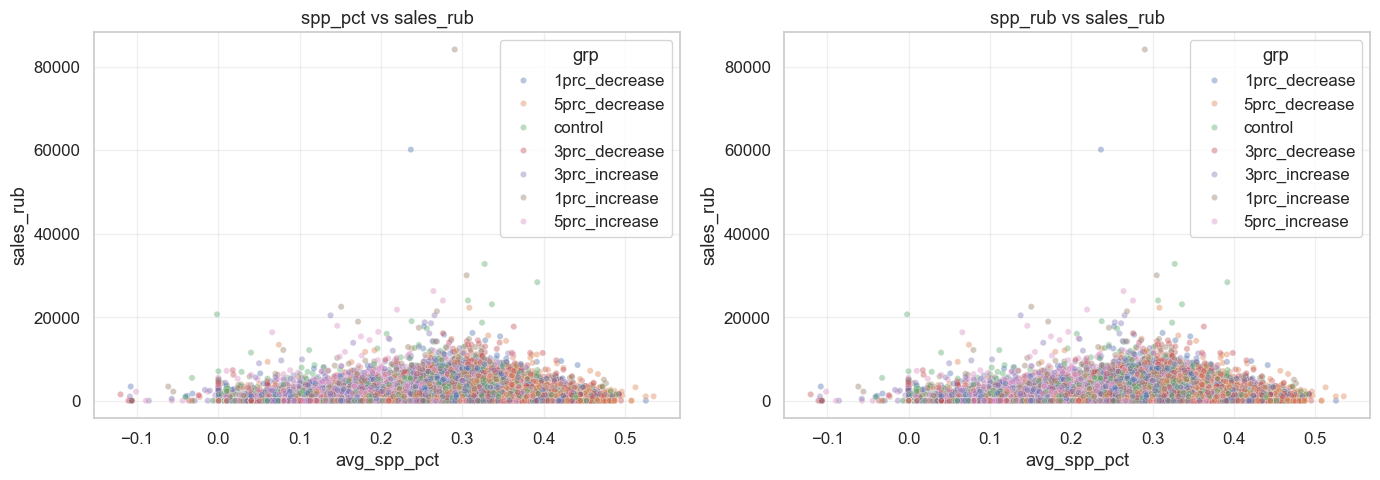

In [41]:
sample_scatter(user_result, frac=0.05)








Вывод:

На scatter-графиках зависимость не линейна и сильно зашумлена, что типично для пользовательских транзакционных данных. Это означает, что финальные выводы нужно делать не по визуальной корреляции, а по аккуратному сравнению агрегированных метрик между группами.

# Проверяем, пересекаются ли клиенты между группами

In [44]:
def check_group_leakage(df, user_col='user_id', group_col='grp'):

    user_groups = df.groupby(user_col)[group_col].nunique()

    leaked_users = user_groups[user_groups > 1]
    
    if len(leaked_users) > 0:
        print(f"обнаружено пересечение {len(leaked_users)} пользователей попали в несколько групп.")

        example_ids = leaked_users.head(3).index.tolist()
        print(f"id с утечкой: {example_ids}")
    else:
        print("успех, группы не пересекаются")
    
    return leaked_users

leakage = check_group_leakage(result)

успех, группы не пересекаются


# Чистка данных
Есть клиенты-"оптовики", которые заказывают очень большое число единиц товара за раз. Таких клиентов считаем выбросами, потому что они не отражают поведение среднего пользователя и могут негативно влиять на однородность данных.

Для повышения устойчивости анализа применяется обработка выбросов:

- пользователи с экстремально большим количеством товаров в заказе удаляются из выборки

- денежные выбросы обрабатываются методом винзоризации (ограничение значений на уровне верхнего порога)

Порог выбросов определяется на основе межквартильного размаха (IQR)

In [46]:
result['created_items_cnt'].value_counts().tail(10)

created_items_cnt
89     1
112    1
92     1
129    1
81     1
104    1
253    1
106    1
113    1
88     1
Name: count, dtype: int64

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def handle_outliers_with_viz(df, column, method='winzorize', threshold=1.5):

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    upper_bound = Q3 + threshold * IQR
    
    stats_before = {
        'Mean': df[column].mean(),
        'Median': df[column].median(),
        'Mode': df[column].mode()[0],
        'Std': df[column].std(),
        'Max': df[column].max()
    }

    if method == 'remove':
        df_final = df[df[column] <= upper_bound].copy()
    elif method == 'winzorize':
        df_final = df.copy()
        df_final[column] = np.where(df_final[column] > upper_bound, upper_bound, df_final[column])
    
    stats_after = {
        'Mean': df_final[column].mean(),
        'Median': df_final[column].median(),
        'Mode': df_final[column].mode()[0],
        'Std': df_final[column].std(),
        'Max': df_final[column].max()
    }

    comparison = pd.DataFrame([stats_before, stats_after], index=['Before', 'After'])
    print(f"\n--- Сравнение статистик для {column} ({method}) ---")
    display(comparison.round(2))
    print(f"Порог чистки: {upper_bound:.2f}")
    
    return df_final


result = handle_outliers_with_viz(result, column='created_items_cnt', method='remove', threshold=3.0)

result = handle_outliers_with_viz(result, column='sales_rub', method='winzorize', threshold=3)

mde = handle_outliers_with_viz(mde, column='gmv_sum', method='remove', threshold=3.0)
mde = handle_outliers_with_viz(mde, column='orders_sum', method='remove', threshold=3.0)


--- Сравнение статистик для created_items_cnt (remove) ---


,Mean,Median,Mode,Std,Max
Before,3.44,2.0,1,3.51,268
After,3.11,2.0,1,2.48,13


Порог чистки: 13.00

--- Сравнение статистик для sales_rub (winzorize) ---


,Mean,Median,Mode,Std,Max
Before,1339.88,1236.25,0.0,1422.02,91252.5
After,1331.23,1236.25,0.0,1363.63,7750.0


Порог чистки: 7750.00

--- Сравнение статистик для gmv_sum (remove) ---


,Mean,Median,Mode,Std,Max
Before,1791.01,1383.75,0.0,2125.97,72511.25
After,1764.67,1375.00,0.0,2021.48,12756.25


Порог чистки: 12756.25

--- Сравнение статистик для orders_sum (remove) ---


,Mean,Median,Mode,Std,Max
Before,6188.21,4218.75,1248.75,5911.66,416788.75
After,5611.83,4128.75,1248.75,4262.18,22868.75


Порог чистки: 22868.75


# Пользователи, которые заказали, но ничего не купили

важной особенностью поведения пользователей является ситуация, когда клиент оформляет заказ, но в итоге ничего не выкупает

Такое поведение приводит к дополнительной нагрузке на логистику и увеличивает операционные издержки

В данном разделе анализируется доля пользователей, которые оформляют заказ, но не совершают фактическую покупку

In [49]:
result[(result['orders_rub'] > 0) & (result['sales_rub'] == 0)].shape

(433494, 11)


--- Анализ конверсии в выкуп по группам ---


,user_id,buyout_conversion,orders_rub,sales_rub,revenue_leakage_pct
grp,,,,,
5prc_decrease,197262,0.6754,4684.6506,1303.2910,0.7218
3prc_decrease,192236,0.6722,4801.9329,1320.4868,0.7250
1prc_decrease,187940,0.6698,4843.5818,1330.0631,0.7254
control,185811,0.6663,4901.4423,1333.4328,0.7280
1prc_increase,183322,0.6643,4896.6055,1333.5113,0.7277
3prc_increase,179679,0.6609,4967.7402,1344.3823,0.7294
5prc_increase,175036,0.6578,5049.6016,1357.5082,0.7312


/var/folders/pr/w4z2x1m903bc7ktytzfw_3wm0000gn/T/ipykernel_25869/3998527836.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=analysis.reset_index(), x='grp', y='buyout_conversion', palette='viridis')


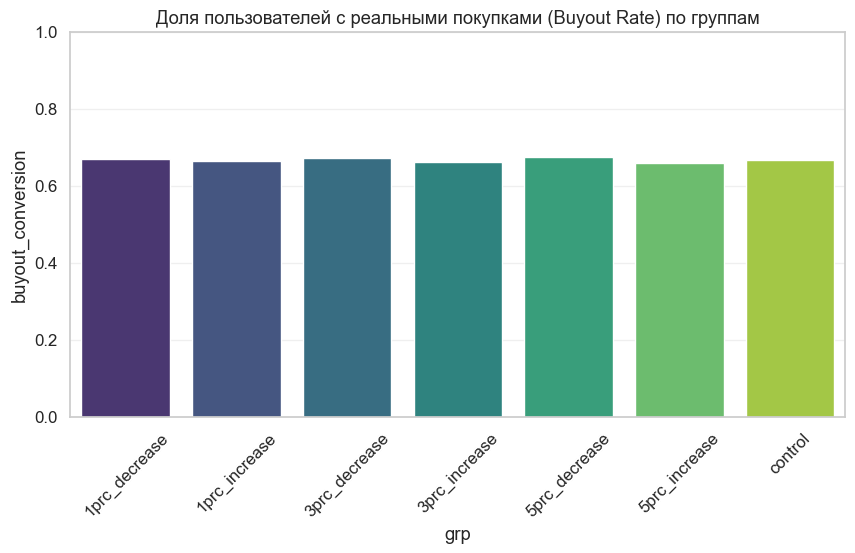

In [50]:
def analyze_zero_sales(df_orig):

    df = df_orig.copy()
    df['is_bought'] = (df['sales_rub'] > 0).astype(int)
    
    analysis = df.groupby('grp').agg({
        'user_id': 'count',
        'is_bought': 'mean', # Это и есть конверсия в выкуп
        'orders_rub': 'mean', # На какую сумму заказали изначально
        'sales_rub': 'mean'   # На какую сумму реально купили
    }).rename(columns={'is_bought': 'buyout_conversion'})
    

    analysis['revenue_leakage_pct'] = 1 - (analysis['sales_rub'] / analysis['orders_rub'])
    
    print("\n--- Анализ конверсии в выкуп по группам ---")
    display(analysis.sort_values(by='buyout_conversion', ascending=False).round(4))
    
    plt.figure(figsize=(10, 5))
    sns.barplot(data=analysis.reset_index(), x='grp', y='buyout_conversion', palette='viridis')
    plt.title('Доля пользователей с реальными покупками (Buyout Rate) по группам')
    plt.xticks(rotation=45)
    plt.ylim(0, 1) 
    plt.show()
    
    return analysis

check = analyze_zero_sales(result)

In [52]:
result_agg = (
    result.groupby("user_id")
      .agg({
          "grp": "first",
          "sales_rub": "sum",
          "orders_rub": "sum"
      })
      .reset_index()
)
result_agg

,user_id,grp,sales_rub,orders_rub
0,00001D81B912895FBADF4A7B8B0663A1,1prc_decrease,0.000000,1666.250000
1,00002120A2324A3026ABBCB45B156B84,control,1686.875000,8245.625000
2,000028899FE7782862D40BB1B87807EE,3prc_increase,0.000000,2735.106201
3,0000294120D3EDEA05301B54521E874E,3prc_decrease,3028.125000,3028.125000
4,0000364E5C3ED38440134DFB08CD8844,control,2428.750000,4998.125000
...,...,...,...,...
1301281,FFFFBEAAD3467E5D017E72166E462FC8,3prc_increase,0.000000,4271.875000
1301282,FFFFCA39F26D0B110256459DCD77B32F,3prc_decrease,2478.125000,5231.875000
1301283,FFFFD8F0FBFA10B99EFE90A5EE13C5DF,5prc_increase,1075.625000,4298.125000
1301284,FFFFF973CFD726CF4D723F7D249B32E0,5prc_increase,1575.462494,3150.924988


In [53]:
mde_agg = (
    mde.groupby("user_id")
      .agg({
          "grp": "first",
          "gmv_sum": "sum",
          "orders_sum": "sum"
      })
      .reset_index()
)
mde_agg

,user_id,grp,gmv_sum,orders_sum
0,00003687F40AB9B083E16D4417A0EC1F,1prc_decrease,11180.000000,11180.000000
1,00003A1CA9A9BBB2F510EB1C3F675327,5prc_increase,3748.750000,3748.750000
2,0000552533CF55CFA753DC58A5081F3D,3prc_increase,3727.500000,11543.750000
3,0000667A56DF76742838400BA34606BD,1prc_decrease,1622.500000,1622.500000
4,0000B41B9AB1A87D7532D14A737F2E66,3prc_decrease,0.000000,2653.750000
...,...,...,...,...
756069,FFFFC73E9BEFF62B08F58094AEAABAC8,3prc_increase,0.000000,26557.500000
756070,FFFFCA39F26D0B110256459DCD77B32F,3prc_decrease,2190.000000,4380.000000
756071,FFFFD8F0FBFA10B99EFE90A5EE13C5DF,5prc_increase,0.000000,3457.500000
756072,FFFFF973CFD726CF4D723F7D249B32E0,5prc_increase,2587.525024,2587.525024


In [54]:
import pandas as pd
import numpy as np
from scipy.stats import norm


# -----------------------------
# 3. новая метрика AOV
# gmv_sum / orders_sum
# учитываем orders_sum = 0
# -----------------------------
mde_agg["aov"] = np.where(
    mde_agg["orders_sum"] == 0,
    0,
    mde_agg["gmv_sum"] / mde_agg["orders_sum"]
)

# -----------------------------
# 4. размеры групп из result
# -----------------------------
group_sizes = result_agg.groupby("grp")["user_id"].nunique()

n_per_group = group_sizes.min()   # берем минимальный размер
print("Group sizes:\n", group_sizes)

# -----------------------------
# 5. параметры теста
# -----------------------------
alpha = 0.05
power = 0.8

n_groups = 6

# Bonferroni correction
alpha_corrected = alpha / n_groups

z_alpha = norm.ppf(1 - alpha_corrected / 2)
z_beta = norm.ppf(power)

# -----------------------------
# функция MDE
# -----------------------------
def calc_mde(metric):

    mean = metric.mean()
    std = metric.std()

    mde = (z_alpha + z_beta) * std * np.sqrt(2 / n_per_group)

    mde_rel = mde / mean

    return {
        "mean": mean,
        "std": std,
        "MDE_abs": mde,
        "MDE_rel_%": mde_rel * 100
    }


# -----------------------------
# 6. считаем MDE
# -----------------------------
metrics = {
    "gmv_sum": mde_agg["gmv_sum"],
    "aov": mde_agg["aov"]
}

results = {}

for name, metric in metrics.items():
    results[name] = calc_mde(metric)

results_df = pd.DataFrame(results).T

print(results_df)

Group sizes:
 grp
1prc_decrease    187940
1prc_increase    183322
3prc_decrease    192236
3prc_increase    179679
5prc_decrease    197262
5prc_increase    175036
control          185811
Name: user_id, dtype: int64
                mean          std    MDE_abs  MDE_rel_%
gmv_sum  2290.043036  2359.303970  27.752320   1.211869
aov         0.404404     0.394557   0.004641   1.147651


# Проверка на гомогенность данных

Перед анализом результатов теста необходимо убедиться, что экспериментальные группы сопоставимы между собой по ключевым показателям.

В данном разделе проводится проверка гомогенности групп по основным метрикам. Для проверки используется непараметрический тест Краскала-Улоллиса, который позволяет сравнить распределения метрик между несколькими независимыми группами.

In [56]:
gom.head()
gom.info()
gom['grp'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 571116 entries, 0 to 571115
Data columns (total 23 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   user_id             571116 non-null  string 
 1   grp                 571116 non-null  string 
 2   bu                  571116 non-null  string 
 3   parent_name         571116 non-null  string 
 4   subject_name        571116 non-null  string 
 5   created_orders_cnt  571116 non-null  uint64 
 6   created_items_cnt   571116 non-null  uint64 
 7   created_items_rub   571116 non-null  float64
 8   bought_items_cnt    571116 non-null  uint64 
 9   bought_items_rub    571116 non-null  float64
 10  spp_rub             571116 non-null  float64
 11  spp_pct             571116 non-null  float64
 12  order_days_cnt      571116 non-null  uint64 
 13  aiv                 571116 non-null  float64
 14  aov                 571116 non-null  float64
 15  upt                 571116 non-nul

grp
3prc_increase    81824
5prc_decrease    81786
5prc_increase    81618
1prc_increase    81551
3prc_decrease    81516
1prc_decrease    81450
control          81371
Name: count, dtype: Int64

В 3 столбцах все значения пропущены - может, это были утерянные в процессе выгрузки данные.
В целом размеры групп одинаковые, отличаются менее, чем на 1%

In [58]:
# не использую spp_pct и spp_rub, тк это относится к переменным теста 
metrics = [
'created_orders_cnt',
'created_items_cnt',
'created_items_rub',
'bought_items_cnt',
'bought_items_rub',
'order_days_cnt',
'aiv',
'aov',
'profit',
'purchase_percent',
'purchase_sum'
]


In [59]:
gom.groupby('grp')[metrics].median() # статистики в целом по метрикам

,created_orders_cnt,created_items_cnt,created_items_rub,bought_items_cnt,bought_items_rub,order_days_cnt,aiv,aov,profit,purchase_percent,purchase_sum
grp,,,,,,,,,,,
1prc_decrease,4.0,4.0,5441.25,2.0,2125.000000,1.0,1503.125000,1503.125000,6410687.5,57.0,23078500.0
1prc_increase,4.0,4.0,5395.00,2.0,2122.500000,1.0,1499.193726,1499.193726,6377808.0,57.0,22902700.0
3prc_decrease,4.0,4.0,5367.50,2.0,2123.750000,1.0,1502.500000,1502.500000,6484988.0,57.0,23303050.0
3prc_increase,4.0,4.0,5411.25,2.0,2133.750000,1.0,1500.000000,1500.000000,6413250.5,57.0,22919850.0
5prc_decrease,4.0,4.0,5420.00,2.0,2113.750000,1.0,1504.252232,1504.252232,6467850.0,57.0,23242950.0
5prc_increase,4.0,4.0,5421.25,2.0,2151.250000,1.0,1508.096591,1508.096591,6344788.5,57.0,22734750.0
control,4.0,4.0,5422.50,2.0,2111.049957,1.0,1496.250000,1496.250000,6444316.0,57.0,23143700.0


In [60]:
# Для проверки используется тест Kruskal–Wallis
# Гипотезы теста:
# H0: распределения метрики одинаковые во всех группах
# H1: хотя бы одна группа отличается
# Если по каждой метрике p-value > 0.05 - различий нет и группы гомогенны

from scipy.stats import kruskal

for metric in metrics:
    
    groups = [
        gom[gom['grp'] == g][metric]
        for g in gom['grp'].unique()
    ]
    
    stat, p = kruskal(*groups)
    
    print(metric, "p-value =", round(p,4))

created_orders_cnt p-value = 0.5846
created_items_cnt p-value = 0.5846
created_items_rub p-value = 0.7266
bought_items_cnt p-value = 0.1557
bought_items_rub p-value = 0.0669
order_days_cnt p-value = 0.5527
aiv p-value = 0.0884
aov p-value = 0.0884
profit p-value = 0.0
purchase_percent p-value = 0.0
purchase_sum p-value = 0.0


In [61]:
# тест показал p-value = 0.0 для трех метрик, но может, из-за большого объема выборки это завышенная чувствительность
gom.groupby('grp')[['profit','purchase_percent','purchase_sum']].mean()

,profit,purchase_percent,purchase_sum
grp,,,
1prc_decrease,8.801996e+06,58.986618,3.159514e+07
1prc_increase,8.777775e+06,59.023409,3.138116e+07
3prc_decrease,8.892149e+06,59.153663,3.188179e+07
3prc_increase,8.812529e+06,58.873680,3.143630e+07
5prc_decrease,8.856722e+06,59.251058,3.180343e+07
5prc_increase,8.749853e+06,58.800510,3.122199e+07
control,8.830840e+06,58.846579,3.159635e+07


По большинству метрик статистически значимых различий между группами выявлено не было, что свидетельствует о корректной рандомизации пользователей

Для некоторых метрик тест показал статистически значимые различия. Однако анализ средних значений показывает, что различия между группами находятся в пределах 1%

При таком размере выборки статистические тесты становятся чувствительными даже к очень небольшим отклонениям. Поэтому при интерпретации результатов важно учитывать не только p-value, но и размер эффекта

С практической точки зрения различия между группами можно считать незначительными, поэтому группы можно считать сопоставимыми

### вывод: группы гомогенны
#### визуализации распределений данных:

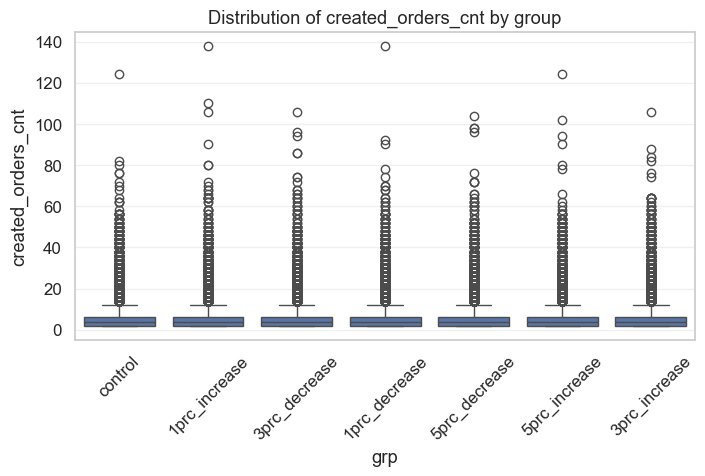

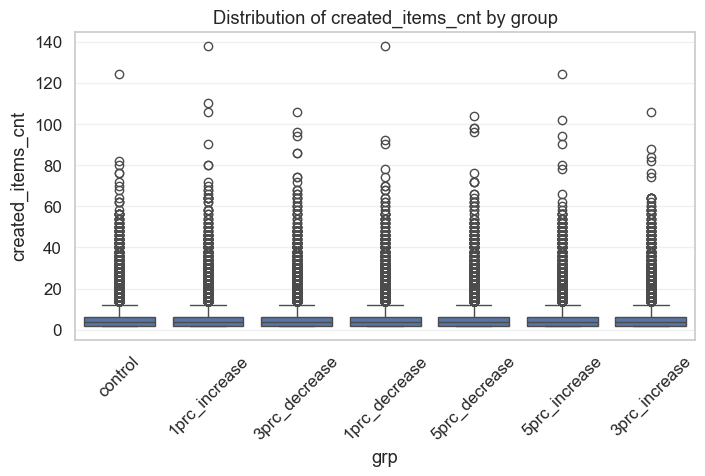

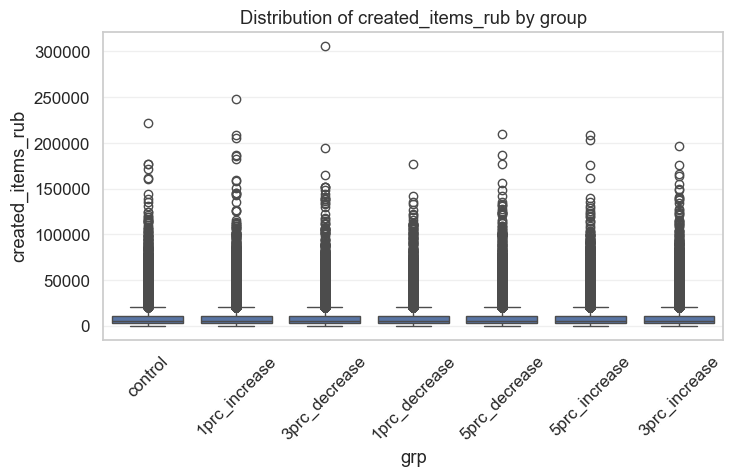

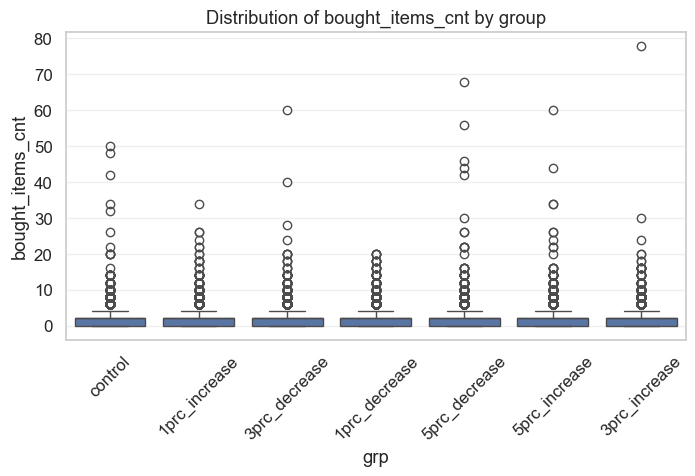

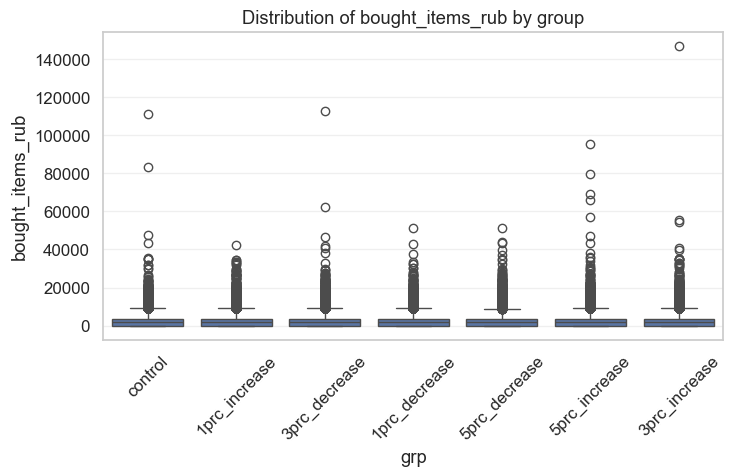

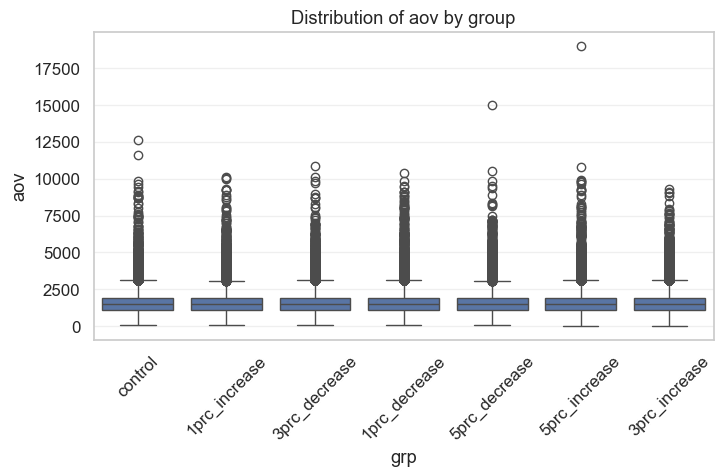

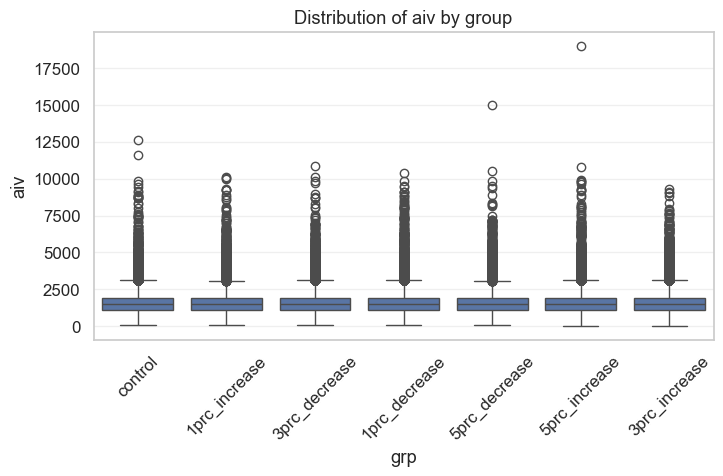

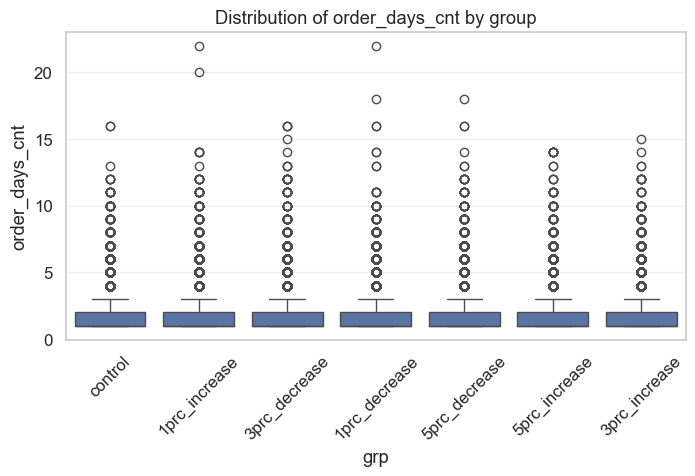

In [63]:
# распределение данных по каждой метрике по группам - видно, что за исключением выбросов данные 
# между группами схожи
import seaborn as sns
import matplotlib.pyplot as plt

metrics = [
'created_orders_cnt',
'created_items_cnt',
'created_items_rub',
'bought_items_cnt',
'bought_items_rub',
'aov',
'aiv',
'order_days_cnt'
]

for metric in metrics:
    
    plt.figure(figsize=(8,4))
    
    sns.boxplot(
        data=gom,
        x='grp',
        y=metric
    )
    
    plt.title(f'Distribution of {metric} by group')
    plt.xticks(rotation=45)
    
    plt.show()

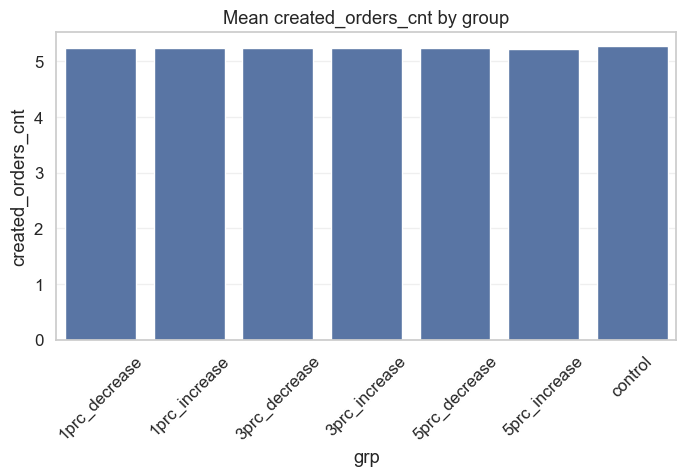

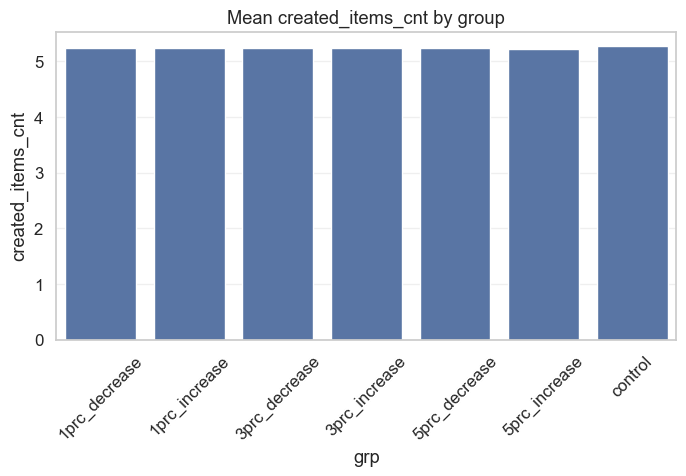

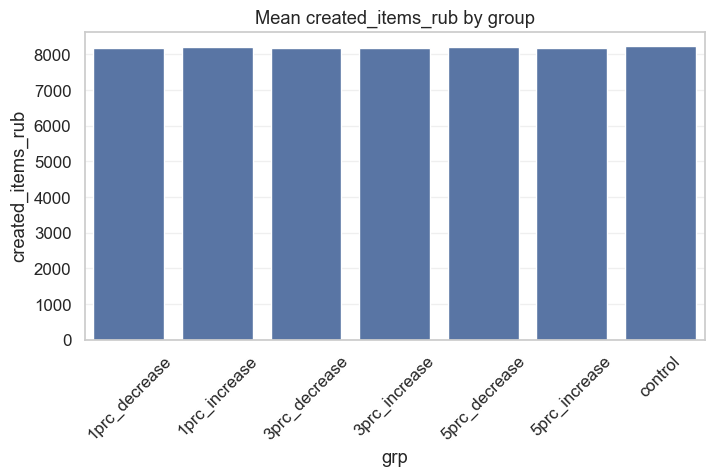

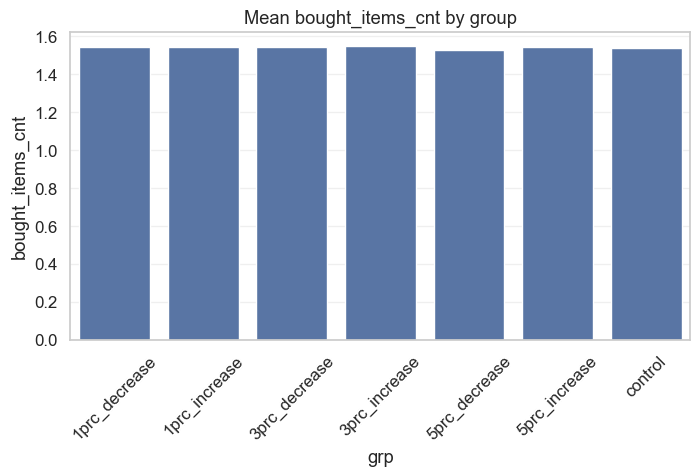

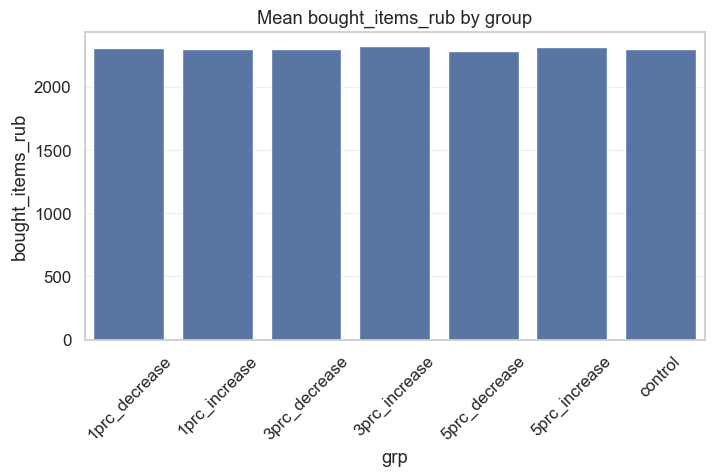

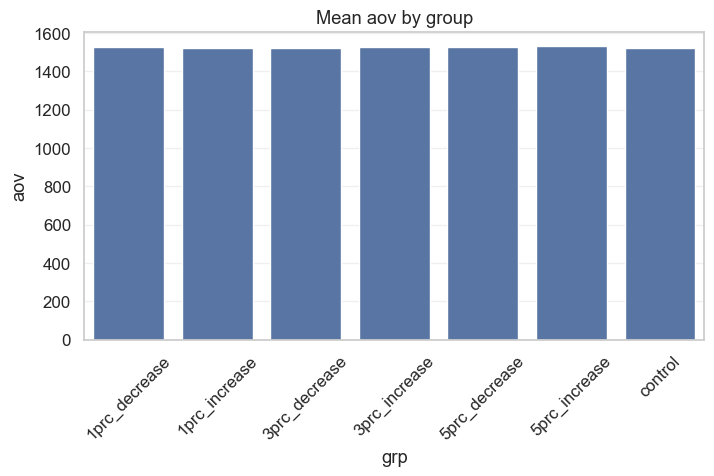

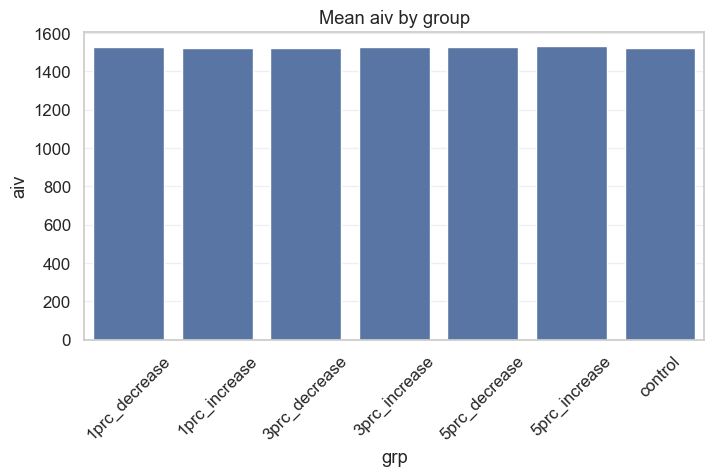

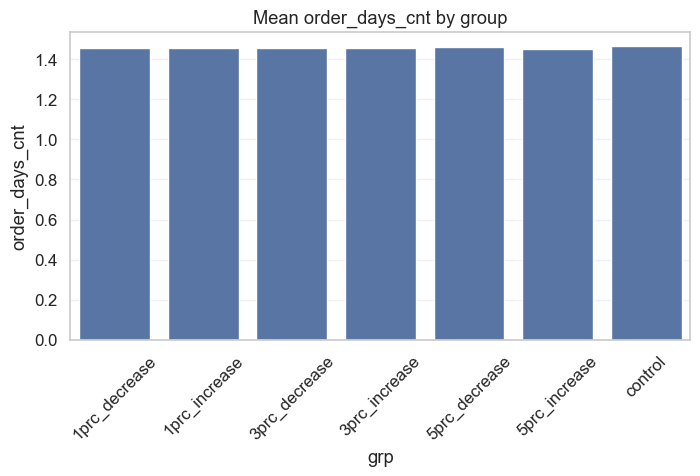

In [64]:
# сравним средние:

mean_metrics = gom.groupby('grp')[metrics].mean().reset_index()

for metric in metrics:
    
    plt.figure(figsize=(8,4))
    
    sns.barplot(
        data=mean_metrics,
        x='grp',
        y=metric
    )
    
    plt.title(f'Mean {metric} by group')
    plt.xticks(rotation=45)
    
    plt.show()

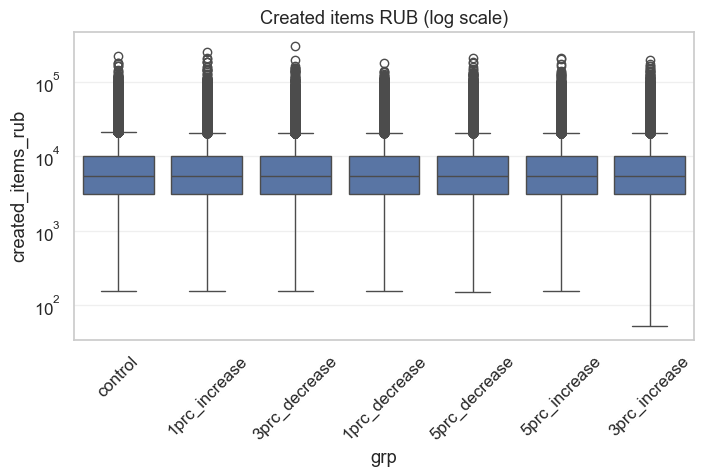

In [65]:
plt.figure(figsize=(8,4))

sns.boxplot(data=gom, x='grp', y='created_items_rub')

plt.yscale('log')

plt.title("Created items RUB (log scale)")
plt.xticks(rotation=45)

plt.show()

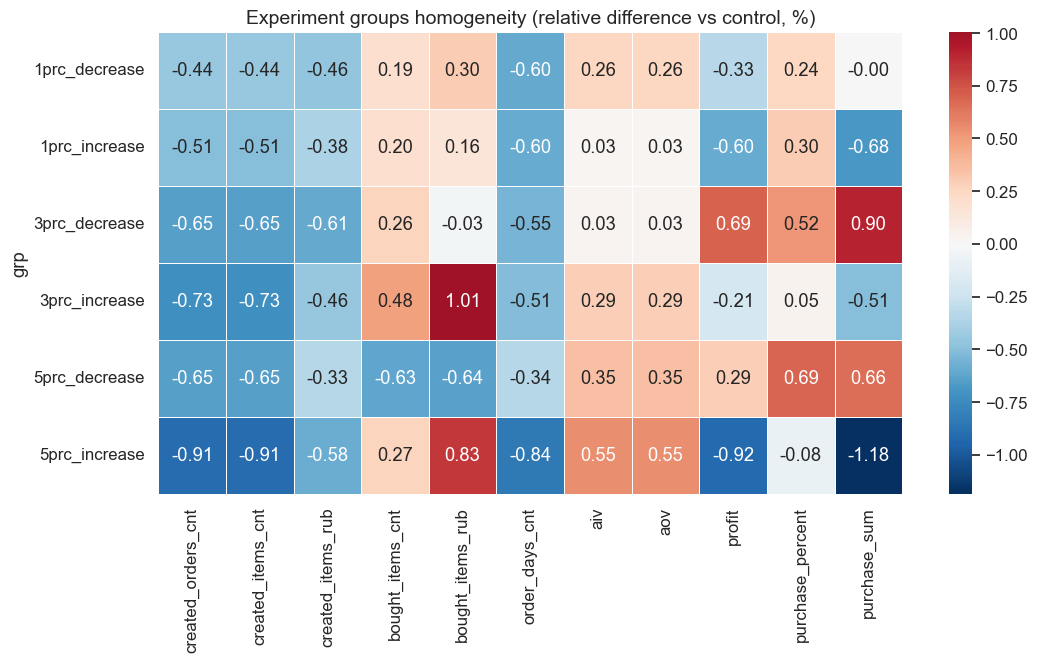

In [66]:
# матрица показывает, на сколько % значение метрики в группе отличается от контроля

metrics = [
'created_orders_cnt',
'created_items_cnt',
'created_items_rub',
'bought_items_cnt',
'bought_items_rub',
'order_days_cnt',
'aiv',
'aov',
'profit',
'purchase_percent',
'purchase_sum'
]

mean_metrics = gom.groupby('grp')[metrics].mean()

control = mean_metrics.loc['control']

relative_diff = (mean_metrics - control) / control * 100

relative_diff = relative_diff.drop('control')

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

sns.heatmap(
    relative_diff,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    linewidths=0.5
)

plt.title("Experiment groups homogeneity (relative difference vs control, %)", fontsize=14)

plt.show()

# Тесты

После проверки корректности данных проводится статистическая оценка результатов эксперимента

Анализ выполняется на уровне пользователей. Для каждой экспериментальной группы рассчитываются:

- средние значения метрик

- доверительные интервалы

- разница относительно контрольной группы

- аплифт

Для проверки стат. значимости используется  t-test, который позволяет сравнивать средние значения двух групп при возможном различии дисперсий

Дополнительно применяется коррекция на множественные сравнения (FDR), чтобы снизить вероятность ложноположительных результатов

In [68]:
result

,grp,user_id,bu,parent_name,subject_name,created_items_cnt,spp_pct,spp_rub,orders_rub,sales_rub,supplier_price
0,5prc_decrease,2958380FD4A91A445780DE061A44E090,Fashion,Одежда,Джинсы,3,0.301519,2259.375000,5643.750000,0.000000,7653.125000
1,5prc_decrease,233982E5C3D7464C299B00605B460E9A,Fashion,Одежда,Джинсы,4,0.357019,5888.750000,10742.500000,2090.000000,16631.250000
2,1prc_decrease,EB001560B92FD8EA77C77AAA2F2A12EA,Fashion,Одежда,Джинсы,5,0.322821,1967.500000,4281.250000,803.125000,6085.625000
3,5prc_increase,9B9F327574FD2292D7D51F577D6A08E9,Fashion,Одежда,Джинсы,4,0.385408,5535.625000,8994.375000,2830.000000,13808.750000
4,1prc_increase,644F9E4A9A78F45C98FADC9913B7C83D,Fashion,Одежда,Джинсы,1,0.243636,335.000000,1106.875000,1106.875000,1375.000000
...,...,...,...,...,...,...,...,...,...,...,...
1328874,control,1AC88C4D7407F29F9C9C877BB1A68501,Fashion,Одежда,Джинсы,2,0.305158,1050.000000,2465.000000,909.375000,3316.875000
1328875,5prc_decrease,D1F75BB23054D0A1401A6CBCD7A9EE30,Fashion,Одежда,Джинсы,5,0.277781,2479.375000,6655.000000,2401.250000,8751.250000
1328876,control,A129BF8678D11633EE385D6DFEDBE616,Fashion,Одежда,Джинсы,3,0.133972,1161.719055,7509.631348,2502.575073,8671.350403
1328877,5prc_decrease,B16E0AE709CBC93A4146322A6E4D8F60,Fashion,Одежда,Джинсы,1,0.348437,1254.375000,2495.625000,0.000000,3600.000000


In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")


def prepare_user_level(result: pd.DataFrame) -> pd.DataFrame:
    user_df = (
        result.groupby(["grp", "user_id"], as_index=False)
              .agg(
                  sales_rub=("sales_rub", "sum"),
                  orders_rub=("orders_rub", "sum")
              )
    )
    user_df["purchase_rate"] = np.where(
        user_df["orders_rub"] > 0,
        user_df["sales_rub"] / user_df["orders_rub"],
        np.nan
    )
    return user_df

In [70]:
# Welch t-test + аналитический CI

def welch_test_with_ci(x, y, alpha=0.05):
    x = pd.Series(x).dropna().values
    y = pd.Series(y).dropna().values

    nx, ny = len(x), len(y)
    mx, my = x.mean(), y.mean()
    vx, vy = x.var(ddof=1), y.var(ddof=1)

    diff = mx - my
    se = np.sqrt(vx / nx + vy / ny)

    # для больших выборок нормальная аппроксимация более чем достаточна
    z = 1.959963984540054
    ci_low = diff - z * se
    ci_high = diff + z * se

    _, p_value = ttest_ind(x, y, equal_var=False)

    return {
        "mean_test": mx,
        "mean_control": my,
        "diff": diff,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "p_value": p_value,
        "n_test": nx,
        "n_control": ny
    }



# Тесты по всем группам и метрикам vs control

def run_tests_vs_control(
    user_df: pd.DataFrame,
    metrics=("sales_rub", "purchase_rate"),
    control_name="control",
    alpha=0.05
) -> pd.DataFrame:
    rows = []

    for metric in metrics:
        control = user_df.loc[user_df["grp"] == control_name, metric].dropna()

        for grp in sorted(user_df["grp"].unique()):
            test = user_df.loc[user_df["grp"] == grp, metric].dropna()

            if grp == control_name:
                mean_control = control.mean()
                rows.append({
                    "metric": metric,
                    "grp": grp,
                    "n": len(control),
                    "mean": mean_control,
                    "mean_ci_low": np.nan,
                    "mean_ci_high": np.nan,
                    "diff_vs_control": 0.0,
                    "diff_ci_low": 0.0,
                    "diff_ci_high": 0.0,
                    "uplift_pct_vs_control": 0.0,
                    "p_value": np.nan
                })
            else:
                res = welch_test_with_ci(test, control, alpha=alpha)

                uplift = (
                    res["diff"] / res["mean_control"] * 100
                    if res["mean_control"] != 0 else np.nan
                )

                rows.append({
                    "metric": metric,
                    "grp": grp,
                    "n": res["n_test"],
                    "mean": res["mean_test"],
                    "mean_ci_low": np.nan,   # отдельно не считаем, основной CI у diff
                    "mean_ci_high": np.nan,
                    "diff_vs_control": res["diff"],
                    "diff_ci_low": res["ci_low"],
                    "diff_ci_high": res["ci_high"],
                    "uplift_pct_vs_control": uplift,
                    "p_value": res["p_value"]
                })

    out = pd.DataFrame(rows)

    mask = out["grp"] != control_name
    reject, p_adj, _, _ = multipletests(
        out.loc[mask, "p_value"],
        alpha=alpha,
        method="fdr_bh"
    )
    out.loc[mask, "p_adj"] = p_adj
    out.loc[mask, "significant"] = reject
    out.loc[~mask, ["p_adj", "significant"]] = np.nan

    return out.sort_values(["metric", "grp"]).reset_index(drop=True)


# CI для среднего внутри группы

def group_mean_ci(user_df: pd.DataFrame, metrics=("sales_rub", "purchase_rate")) -> pd.DataFrame:
    rows = []
    z = 1.959963984540054

    for metric in metrics:
        for grp, sub in user_df.groupby("grp"):
            x = sub[metric].dropna().values
            n = len(x)
            mean = x.mean()
            se = x.std(ddof=1) / np.sqrt(n)
            rows.append({
                "metric": metric,
                "grp": grp,
                "n": n,
                "mean": mean,
                "mean_ci_low": mean - z * se,
                "mean_ci_high": mean + z * se
            })

    return pd.DataFrame(rows)

In [71]:

def plot_group_means(mean_ci_df: pd.DataFrame):
    metrics = mean_ci_df["metric"].unique()
    fig, axes = plt.subplots(1, len(metrics), figsize=(8 * len(metrics), 5))
    if len(metrics) == 1:
        axes = [axes]

    for ax, metric in zip(axes, metrics):
        sub = mean_ci_df[mean_ci_df["metric"] == metric].copy()

        sns.barplot(data=sub, x="grp", y="mean", ax=ax)
        ax.errorbar(
            x=np.arange(len(sub)),
            y=sub["mean"],
            yerr=[sub["mean"] - sub["mean_ci_low"], sub["mean_ci_high"] - sub["mean"]],
            fmt="none",
            capsize=4
        )
        ax.set_title(f"{metric}: среднее по группам")
        ax.set_xlabel("")
        ax.tick_params(axis="x", rotation=30)

    plt.tight_layout()
    plt.show()


def plot_uplift_forest(test_results: pd.DataFrame, control_name="control"):
    metrics = test_results["metric"].unique()
    fig, axes = plt.subplots(len(metrics), 1, figsize=(10, 4 * len(metrics)))
    if len(metrics) == 1:
        axes = [axes]

    for ax, metric in zip(axes, metrics):
        sub = test_results[
            (test_results["metric"] == metric) &
            (test_results["grp"] != control_name)
        ].copy()

        control_mean = test_results[
            (test_results["metric"] == metric) &
            (test_results["grp"] == control_name)
        ]["mean"].iloc[0]

        sub["uplift_ci_low_pct"] = sub["diff_ci_low"] / control_mean * 100
        sub["uplift_ci_high_pct"] = sub["diff_ci_high"] / control_mean * 100
        sub = sub.sort_values("uplift_pct_vs_control")

        ax.axvline(0, linestyle="--")
        ax.errorbar(
            x=sub["uplift_pct_vs_control"],
            y=np.arange(len(sub)),
            xerr=[
                sub["uplift_pct_vs_control"] - sub["uplift_ci_low_pct"],
                sub["uplift_ci_high_pct"] - sub["uplift_pct_vs_control"]
            ],
            fmt="o",
            capsize=4
        )
        ax.set_yticks(np.arange(len(sub)))
        ax.set_yticklabels(sub["grp"])
        ax.set_title(f"{metric}: uplift vs control (%)")

    plt.tight_layout()
    plt.show()

,metric,grp,n,mean,mean_ci_low,mean_ci_high
7,purchase_rate,1prc_decrease,187940,0.3759,0.3743,0.3776
8,purchase_rate,1prc_increase,183322,0.3742,0.3725,0.3760
9,purchase_rate,3prc_decrease,192236,0.3773,0.3757,0.3790
10,purchase_rate,3prc_increase,179679,0.3720,0.3702,0.3737
11,purchase_rate,5prc_decrease,197262,0.3808,0.3792,0.3825
12,purchase_rate,5prc_increase,175036,0.3691,0.3673,0.3708
13,purchase_rate,control,185811,0.3742,0.3725,0.3759
0,sales_rub,1prc_decrease,187940,"1,330.0631","1,323.9208","1,336.2054"
1,sales_rub,1prc_increase,183322,"1,333.5113","1,327.2651","1,339.7576"
2,sales_rub,3prc_decrease,192236,"1,320.4868","1,314.4644","1,326.5091"


,metric,grp,n,mean,diff_vs_control,diff_ci_low,diff_ci_high,uplift_pct_vs_control,p_value,p_adj,significant
0,purchase_rate,1prc_decrease,187940,0.3759,0.0017,-0.0007,0.0041,0.4577,0.1609,0.2145,False
1,purchase_rate,1prc_increase,183322,0.3742,0.0000,-0.0024,0.0024,0.0045,0.9890,0.9890,False
2,purchase_rate,3prc_decrease,192236,0.3773,0.0031,0.0007,0.0055,0.8271,0.0109,0.0217,True
3,purchase_rate,3prc_increase,179679,0.3720,-0.0023,-0.0047,0.0002,-0.6045,0.0673,0.1010,False
4,purchase_rate,5prc_decrease,197262,0.3808,0.0066,0.0042,0.0090,1.7666,0.0000,0.0000,True
5,purchase_rate,5prc_increase,175036,0.3691,-0.0051,-0.0076,-0.0027,-1.3740,0.0000,0.0001,True
6,purchase_rate,control,185811,0.3742,0.0000,0.0000,0.0000,0.0000,NaN,NaN,NaN
7,sales_rub,1prc_decrease,187940,"1,330.0631",-3.3697,-12.1127,5.3733,-0.2527,0.4500,0.5400,False
8,sales_rub,1prc_increase,183322,"1,333.5113",0.0785,-8.7379,8.8949,0.0059,0.9861,0.9890,False
9,sales_rub,3prc_decrease,192236,"1,320.4868",-12.9461,-21.6053,-4.2869,-0.9709,0.0034,0.0081,True


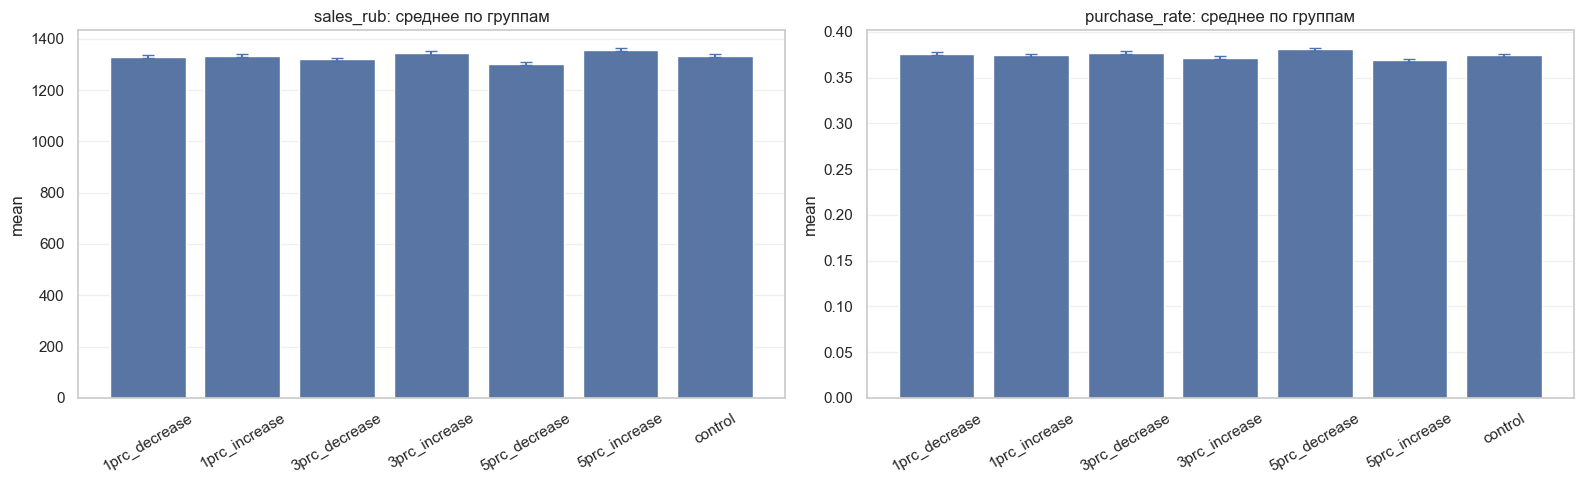

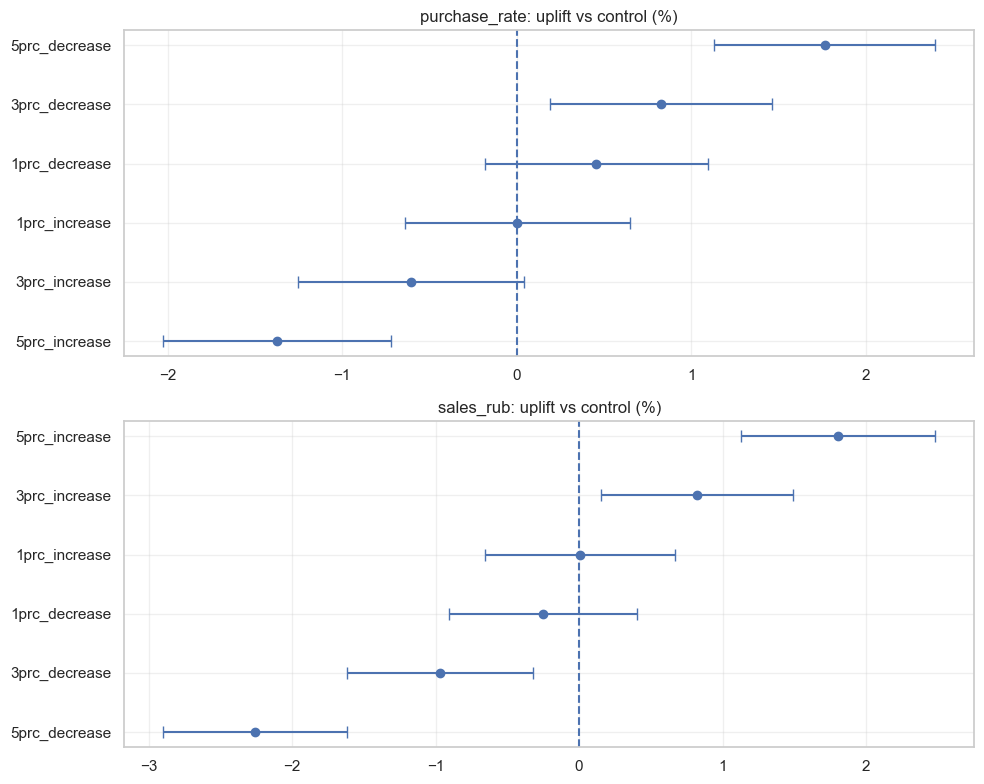

In [72]:
# запуск 
user_df = prepare_user_level(result)

mean_ci_df = group_mean_ci(user_df, metrics=("sales_rub", "purchase_rate"))
test_results = run_tests_vs_control(
    user_df,
    metrics=("sales_rub", "purchase_rate"),
    control_name="control",
    alpha=0.05
)

display(mean_ci_df.sort_values(["metric", "grp"]))
display(test_results[[
    "metric", "grp", "n", "mean",
    "diff_vs_control", "diff_ci_low", "diff_ci_high",
    "uplift_pct_vs_control", "p_value", "p_adj", "significant"
]])

plot_group_means(mean_ci_df)
plot_uplift_forest(test_results)


**Выводы**

В категории **Джинсы** изменение уровня скидки заметно влияет и на **средний выкуп на пользователя**, и на **процент выкупа**. При этом между метриками наблюдается размен.

**Более высокая скидка** (группы, где фактический `spp_pct` выше контроля) **улучшает процент выкупа**: пользователи чаще доводят заказ до фактической покупки. Однако одновременно это приводит к снижению **средней стоимость выкупленных товаров на пользователя**. Иными словами, скидка поддерживает конверсию в выкуп, но ухудшает денежный результат на одного пользователя.

**Более низкая скидка** (группы, где `spp_pct` ниже контроля) дает обратный эффект: **процент выкупа немного снижается**, зато **средний `sales_rub` на пользователя` растет**. Наиболее сильный положительный эффект по денежной метрике показали сценарии со снижением скидки на **3–5 п.п.**

**Итог:** для категории джинсов нельзя смотреть только на одну метрику. Если приоритет — **максимизация выручки на пользователя**, предпочтительнее сценарии с **более низкой скидкой**. Если критично **не просадить процент выкупа**, то слишком сильное снижение скидки несет риск ухудшения второй метрики. Оптимальное бизнес-решение здесь — выбирать компромисс между денежным эффектом и удержанием приемлемого уровня выкупа.


# Аналитическая записка

В рамках работы был проведён анализ эксперимента по изменению уровня скидки на маркетплейсе. На предварительном этапе был выполнен eda-анализ данных, проверка их корректности: проанализирована структура выборки, обработаны выбросы и проверена гомогенность экспериментальных групп. Результаты показали, что пользователи распределены между группами равномерно, а различия по основным метрикам до начала эксперимента отсутствуют или находятся на незначительном уровне. Это позволяет считать рандомизацию корректной и интерпретировать результаты эксперимента как надежные.

Анализ поведения пользователей показал, что изменение уровня скидки влияет на разные этапы покупательского процесса. Увеличение скидки стимулирует пользователей формировать более крупные заказы и несколько повышает вероятность фактического выкупа товаров. Однако при этом часть дополнительного объёма заказов не конвертируется в реальные покупки, что приводит к росту доли возвратов и снижению денежной эффективности на одного пользователя.

Сценарии со снижением уровня скидки демонстрируют обратную динамику: процент выкупа немного уменьшается, но средняя выручка на пользователя увеличивается. Наиболее заметный положительный эффект по денежной метрике наблюдается при снижении скидки на 3–5 п.п. 

В целом результаты эксперимента показывают, что при управлении уровнем скидок важно учитывать баланс между стимулированием спроса и сохранением финансовой эффективности в зависимости от поставленной цели, поскольку чрезмерное увеличение скидки может приводить к росту заказов без сопоставимого увеличения фактических продаж.